Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64
Training samples: 4457
Testing samples: 1115
Text converted into numerical features!
Training feature matrix: (4457, 7403)
Spam Detection Model trained successfully!
Model Accuracy: 97.04%

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      1.00      0.98       966
        Spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97    

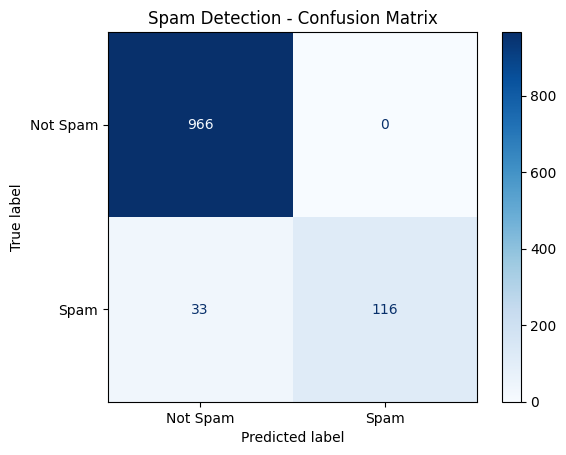

In [18]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

df = df[["label", "message"]].dropna()

df["label"] = df["label"].str.lower().str.strip()
df = df[df["label"].isin(["ham", "spam"])]

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Text converted into numerical features!")
print("Training feature matrix:", X_train_tfidf.shape)

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Spam Detection Model trained successfully!")

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["ham", "spam"]))

def detect_spam(message):
    message_tfidf = vectorizer.transform([message])
    prediction = model.predict(message_tfidf)[0]
    probabilities = model.predict_proba(message_tfidf)[0]

    spam_index = list(model.classes_).index("spam")
    spam_probability = probabilities[spam_index] * 100

    if prediction == "spam":
        result = "SPAM MESSAGE"
    else:
        result = "NOT SPAM (HAM)"

    print("Message:", message)
    print("Prediction:", result)
    print(f"Spam probability: {spam_probability:.2f}%")

    return result

    detect_spam("Congratulations! You won a free iPhone. Click here now!")

    detect_spam("Hi, are we meeting at college tomorrow?")


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    display_labels=["Not Spam", "Spam"],
    cmap="Blues"
)

plt.title("Spam Detection - Confusion Matrix")
plt.show()
